# Phase 2 – Notebook 4: Validation and Calibration

**What this notebook does (in simple words):**
1. Gets delay probabilities from two models: Logistic Regression and the MLP.
2. Checks if the probabilities are **honest**. When a model says "70%", are about 70% of those flights really late?
3. Tries to fix the probabilities: **temperature scaling** (Guo et al. 2017) for the MLP and **Platt scaling** for all models.
4. Reports PR AUC, ROC AUC, ECE, Brier score, and **recall at a fixed precision**.

**Words to know:**
- **ECE (Expected Calibration Error):** the average gap between "what the model says" and "what really happens". Lower is better. 0 is perfect.
- **Brier score:** the average squared error of the probabilities. Lower is better.
- **Temperature scaling:** divide the network's raw scores (logits) by one number T. If T > 1 the network becomes less sure of itself.
- **Platt scaling:** fit a tiny logistic regression on top of the model's scores.

**Rule:** every calibration fix is fitted on the **validation set only** and then tested on the test set.

In [1]:
import sys, os, time
from pathlib import Path

# Work from the project root so imports and paths always work
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

metrics_dir = ROOT / "reports" / "metrics"
fig_dir = ROOT / "reports" / "figures"
metrics_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)


def to_md(df, digits=4):
    """Turn a DataFrame into a markdown table (used for the report)."""
    cols = list(df.columns)
    lines = ["| " + " | ".join(str(c) for c in cols) + " |",
             "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        cells = [f"{v:.{digits}f}" if isinstance(v, (float, np.floating)) else str(v) for v in r.values]
        lines.append("| " + " | ".join(cells) + " |")
    return "\n".join(lines) + "\n"


print("Project root:", ROOT)

Project root: /Users/atharvatiwari/Desktop/flight-delay-prediction


## 1. Load data
Same data and same time split as before.

In [2]:
from src.data_loader import load_data
from src.preprocessing import clean_data, create_target
from src.phase2_history_features import add_history_features, PHASE2_NUMERIC_FEATURES, PHASE2_FEATURE_COLUMNS

df_p2, _ = add_history_features(create_target(clean_data(load_data())), train_ratio=0.70)

n = len(df_p2)
train_end, val_end = int(n * 0.70), int(n * 0.85)
train_df = df_p2.iloc[:train_end].copy()
val_df   = df_p2.iloc[train_end:val_end].copy()
test_df  = df_p2.iloc[val_end:].copy()
y_train, y_val, y_test = train_df["delayed"].values, val_df["delayed"].values, test_df["delayed"].values

print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")
print(f"Delay rate -> train {y_train.mean():.3f} | validation {y_val.mean():.3f} | test {y_test.mean():.3f}")

Train: 229,142 | Validation: 49,102 | Test: 49,102
Delay rate -> train 0.259 | validation 0.154 | test 0.267


In [3]:
import sklearn
import joblib
import torch
import sys

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: 3.15.2 (main, Oct 25 2026, 16:57:51) [Clang 21.0.0 (clang-2100.3.34.2)]
PyTorch: 2.15.0
Scikit-learn: 1.9.1
Joblib: 1.6.0


## 2. Load the trained models
We use the models that were saved in `models/`, so every notebook talks about exactly the same models.

In [4]:
import joblib
lr_model  = joblib.load(ROOT / "models" / "phase2_logistic_regression.joblib")["model"]
print("Loaded Logistic Regression (Phase 2 features).")

Loaded Logistic Regression (Phase 2 features).


In [5]:
import joblib
from src.dl_model import FlightMLP, build_tensors

saved = joblib.load(ROOT / "models" / "dl_artifacts.joblib")
cfg, mapper, scaler, num_cols = saved["config"], saved["mapper"], saved["scaler"], saved["numeric_cols"]

mlp = FlightMLP(
    num_carriers=mapper.num_classes("carrier"),
    num_origins=mapper.num_classes("origin"),
    num_dests=mapper.num_classes("dest"),
    num_numeric=len(num_cols),
    carrier_dim=cfg["carrier_dim"], origin_dim=cfg["origin_dim"],
    dest_dim=cfg["dest_dim"], dropout=cfg["dropout"],
)
mlp.load_state_dict(torch.load(ROOT / "models" / "dl_mlp_embeddings.pt"))
mlp.eval()   # important: switch off dropout, use BatchNorm in test mode
print("Loaded the saved MLP. Best epoch during training:", saved["best_epoch"])

Loaded the saved MLP. Best epoch during training: 3


## 3. Get probabilities on validation and test
For each model we keep two arrays: validation probabilities (used to fit the fixes) and test probabilities (used only to judge).

In [6]:
tensors_val  = build_tensors(val_df,  mapper, scaler, num_cols, is_train=False)
tensors_test = build_tensors(test_df, mapper, scaler, num_cols, is_train=False)

val_logits  = mlp.predict_logits(*tensors_val)
test_logits = mlp.predict_logits(*tensors_test)

raw = {
    "Logistic Regression": (lr_model.predict_proba(val_df[PHASE2_FEATURE_COLUMNS])[:, 1],
                            lr_model.predict_proba(test_df[PHASE2_FEATURE_COLUMNS])[:, 1]),
    "PyTorch MLP":         (mlp.predict_proba(*tensors_val), mlp.predict_proba(*tensors_test)),
}
for name, (pv, pt) in raw.items():
    print(f"{name:20s} val mean prob {pv.mean():.3f} | test mean prob {pt.mean():.3f}")

Logistic Regression  val mean prob 0.275 | test mean prob 0.245
PyTorch MLP          val mean prob 0.300 | test mean prob 0.290


## 4. Important check: the delay rate changed between validation and test
The validation period has far fewer delays than the test period. A calibration fix learns the validation rate. If the test rate is different, the fix can move the probabilities in the wrong direction. This table shows the problem clearly.

In [7]:
diag = []
for name, (pv, pt) in raw.items():
    diag.append({"Model": name,
                 "Val: mean predicted": pv.mean(), "Val: real delay rate": y_val.mean(),
                 "Test: mean predicted": pt.mean(), "Test: real delay rate": y_test.mean()})
pd.DataFrame(diag).round(3)

,Model,Val: mean predicted,Val: real delay rate,Test: mean predicted,Test: real delay rate
0,Logistic Regression,0.275,0.154,0.245,0.267
1,PyTorch MLP,0.300,0.154,0.290,0.267


## 5. Fit the calibration fixes (validation only)
- **Temperature scaling** for the MLP (one number T, learned by minimizing log loss on validation).
- **Platt scaling** for all three models.

Both fixes keep the order of the flights the same, so **PR AUC and ROC AUC do not change**. Only the probability values change.

In [8]:
from src.phase2_calibration import TemperatureScaler, PlattScaler

# Temperature scaling (MLP only, needs logits)
temp_scaler = TemperatureScaler().fit(val_logits, y_val)
print(f"Learned temperature T = {temp_scaler.temperature:.3f}  (T > 1 means: make the MLP less confident)")
mlp_temp = (temp_scaler.transform(val_logits), temp_scaler.transform(test_logits))

# Platt scaling (all models)
platt = {}
for name, (pv, pt) in raw.items():
    sc = PlattScaler().fit(pv, y_val)
    platt[name] = (sc.transform(pv), sc.transform(pt))
print("Platt scaling fitted for:", list(platt.keys()))

Learned temperature T = 0.570  (T > 1 means: make the MLP less confident)
Platt scaling fitted for: ['Logistic Regression', 'PyTorch MLP']


## 6. Results table
For every model and every calibration method we report:
- **ECE** and **Brier** on the test set (calibration quality)
- **PR AUC** and **ROC AUC** (ranking quality)
- **Threshold** chosen on validation so that precision is about 0.40, and the **real precision and recall** we get on test with that threshold
- **Max recall @ precision ≥ 0.40**: the best recall the model can reach on test while keeping precision at 0.40 or more (from the test PR curve). This describes the model. It is **not** used to choose a threshold.

In [9]:
from sklearn.metrics import precision_recall_curve
from src.phase2_calibration import compute_ece
from src.phase2_train import find_threshold_for_precision, evaluate_with_threshold

def full_metrics(name, method, p_val, p_test):
    thr = find_threshold_for_precision(y_val, p_val, target_precision=0.40)
    m = evaluate_with_threshold(y_test, p_test, thr)
    prec, rec, _ = precision_recall_curve(y_test, p_test)
    ok = prec >= 0.40
    return {
        "Model": name, "Calibration": method,
        "ECE": compute_ece(y_test, p_test), "Brier": m["brier_score"],
        "PR AUC": m["pr_auc"], "ROC AUC": m["roc_auc"],
        "Val threshold": thr, "Test precision": m["precision"], "Test recall": m["recall"],
        "Max recall @ prec>=0.40": float(rec[ok].max()) if ok.any() else 0.0,
    }

rows = []
for name in ["Logistic Regression", "PyTorch MLP"]:
    rows.append(full_metrics(name, "None (raw)", *raw[name]))
    if name == "PyTorch MLP":
        rows.append(full_metrics(name, "Temperature scaling", *mlp_temp))
    rows.append(full_metrics(name, "Platt scaling", *platt[name]))

cal_df = pd.DataFrame(rows)
cal_df.to_csv(metrics_dir / "phase2_calibration_results.csv", index=False)
with open(metrics_dir / "phase2_calibration_results.md", "w") as f:
    f.write(to_md(cal_df))
cal_df.round(4)

,Model,Calibration,ECE,Brier,PR AUC,ROC AUC,Val threshold,Test precision,Test recall,Max recall @ prec>=0.40
0,Logistic Regression,None (raw),0.0314,0.1785,0.4695,0.6676,0.4842,0.6453,0.1825,0.5438
1,Logistic Regression,Platt scaling,0.1289,0.1964,0.4695,0.6676,0.2716,0.6465,0.1822,0.5438
2,PyTorch MLP,None (raw),0.0407,0.1788,0.4723,0.6688,0.4706,0.6041,0.2296,0.5327
3,PyTorch MLP,Temperature scaling,0.0722,0.1837,0.4723,0.6688,0.4480,0.6039,0.2302,0.5327
4,PyTorch MLP,Platt scaling,0.1175,0.1925,0.4723,0.6688,0.2535,0.6027,0.2320,0.5327


## 7. Recall at different precision targets
This answers: "If we want our delay alerts to be right at least 30%, 40% or 50% of the time, how many real delays can each model catch?" (Raw probabilities. Calibration does not change this because the order stays the same.)

In [10]:
targets = [0.30, 0.40, 0.50]
rows = []
for name, (pv, pt) in raw.items():
    prec, rec, _ = precision_recall_curve(y_test, pt)
    row = {"Model": name}
    for tg in targets:
        ok = prec >= tg
        row[f"Max recall @ precision>={tg:.2f}"] = float(rec[ok].max()) if ok.any() else 0.0
    rows.append(row)

recall_df = pd.DataFrame(rows)
recall_df.to_csv(metrics_dir / "phase2_recall_at_precision.csv", index=False)
recall_df.round(4)

,Model,Max recall @ precision>=0.30,Max recall @ precision>=0.40,Max recall @ precision>=0.50
0,Logistic Regression,0.8665,0.5438,0.3569
1,PyTorch MLP,0.8847,0.5327,0.3462


## 8. Reliability curves
A perfect model lies on the dashed diagonal. Points **above** the line mean the model is too cautious (real delays are more frequent than predicted). Points **below** mean it is too confident.

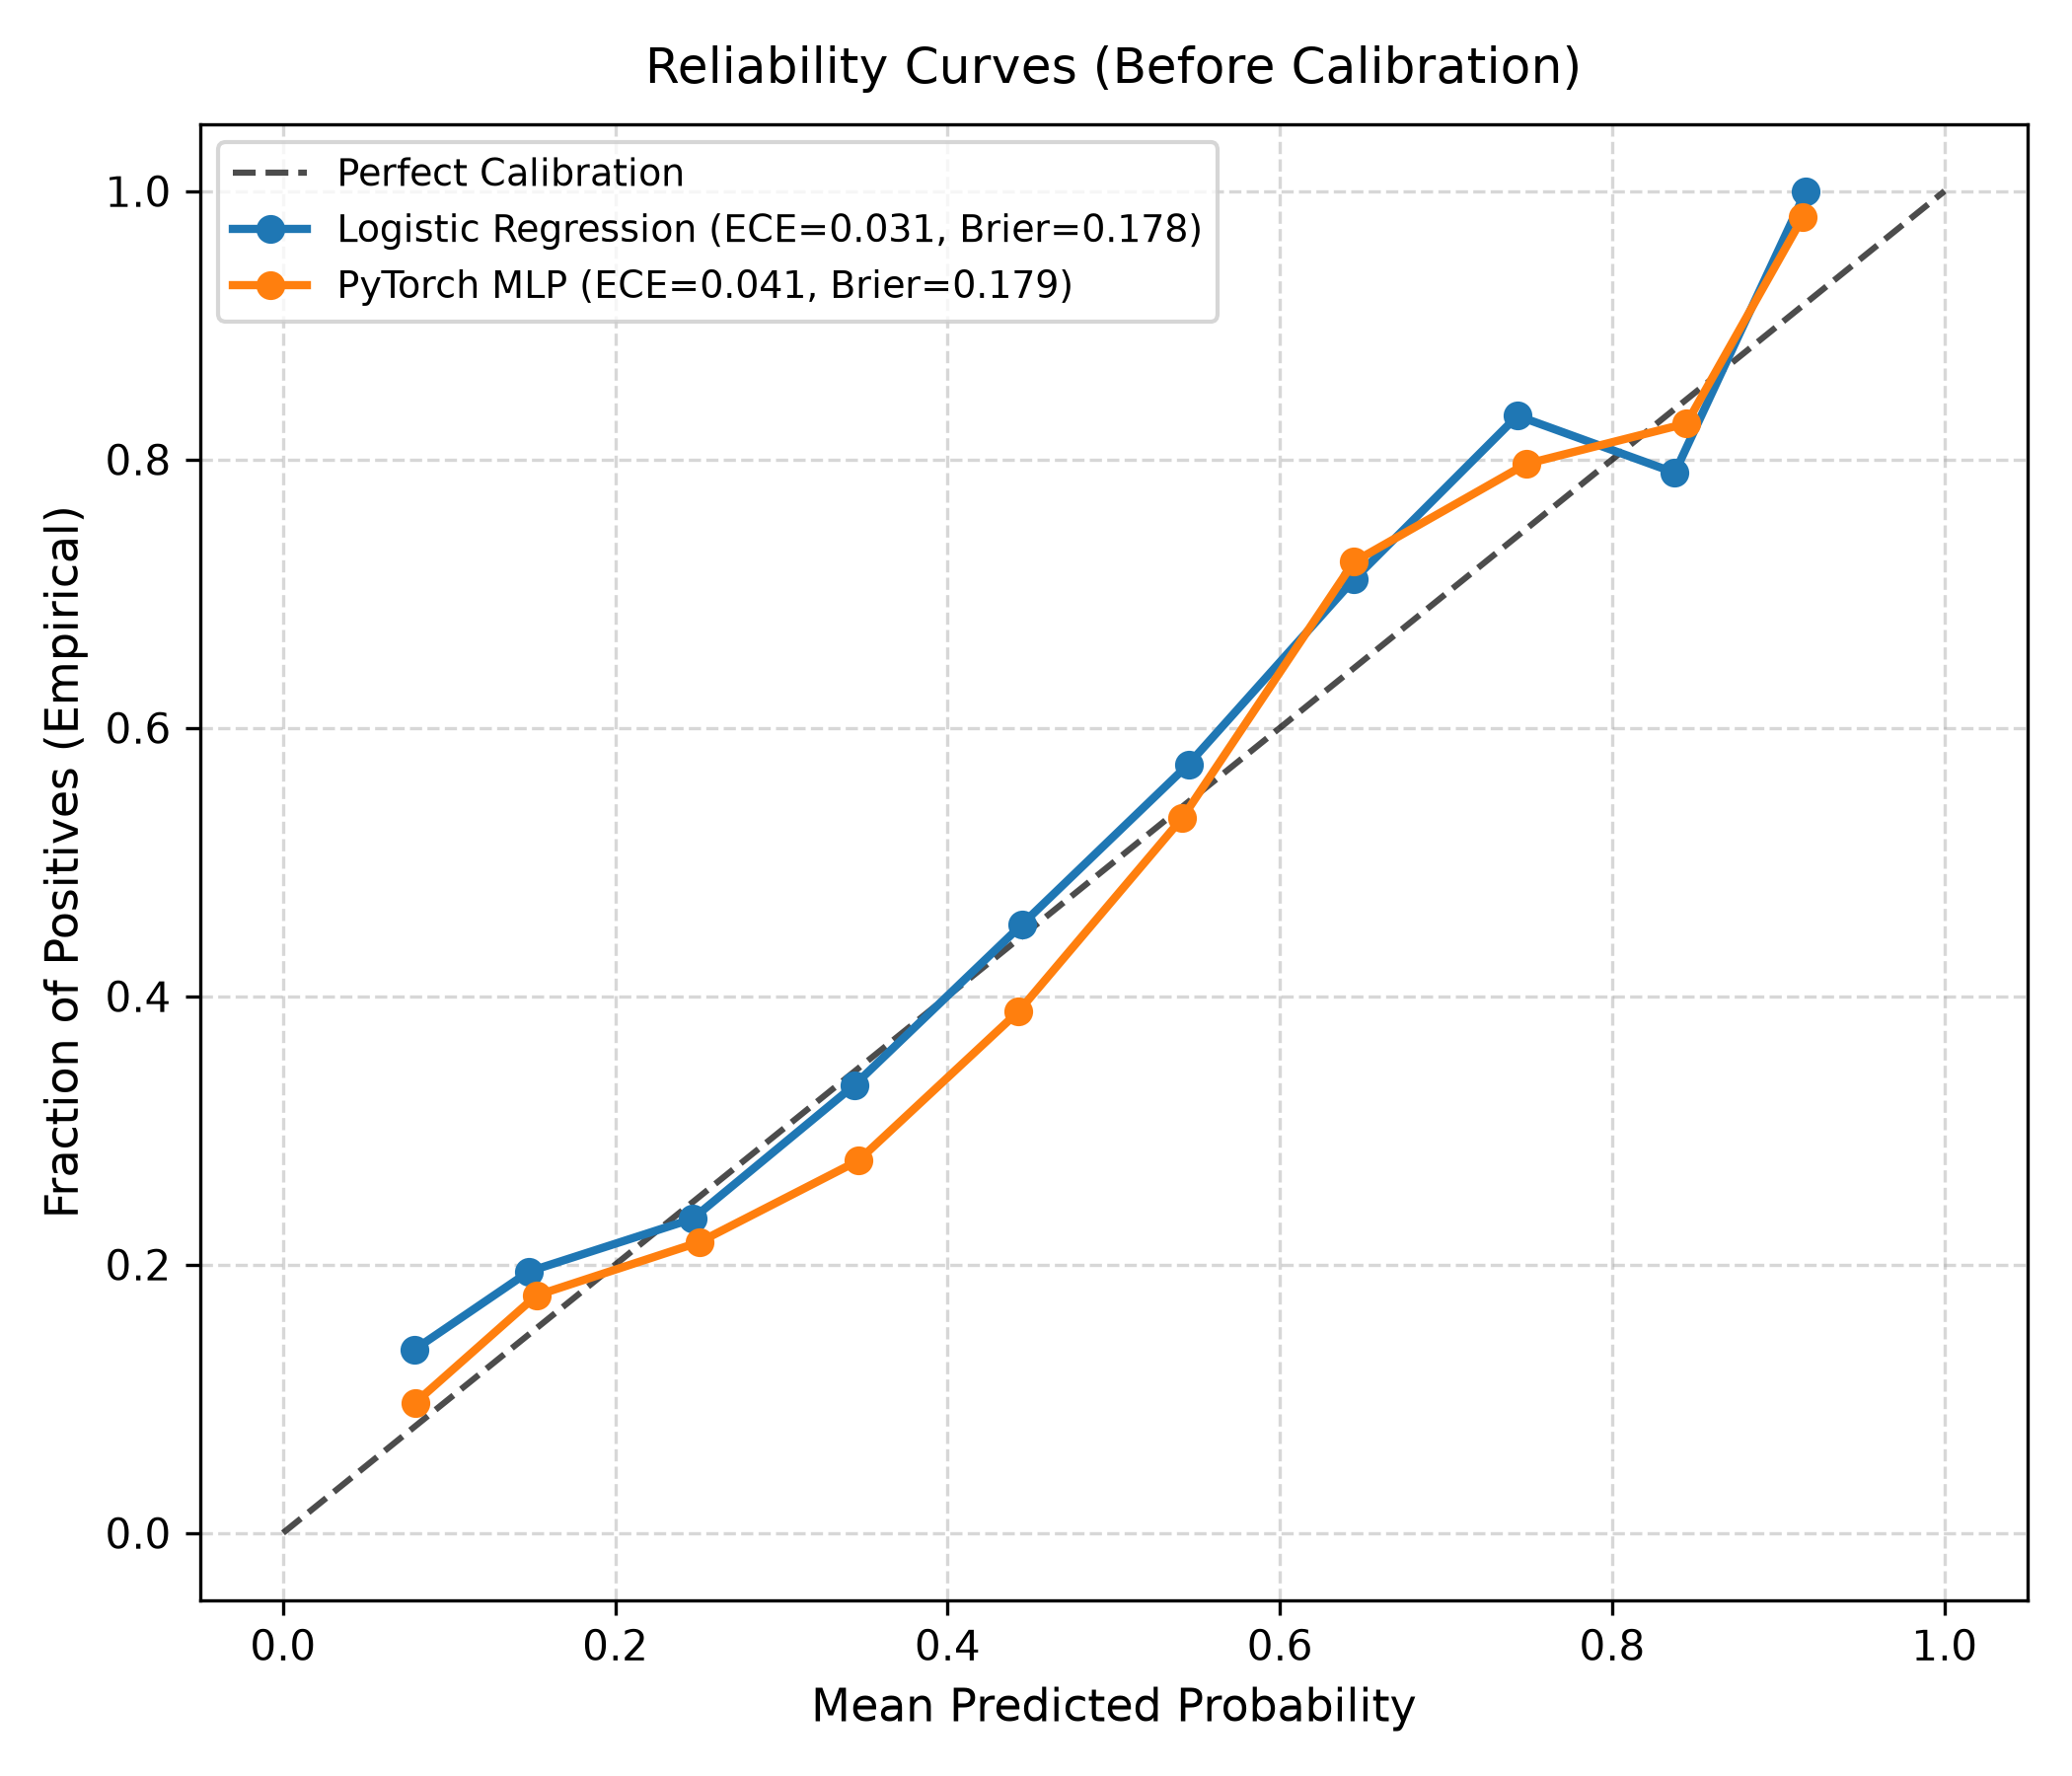

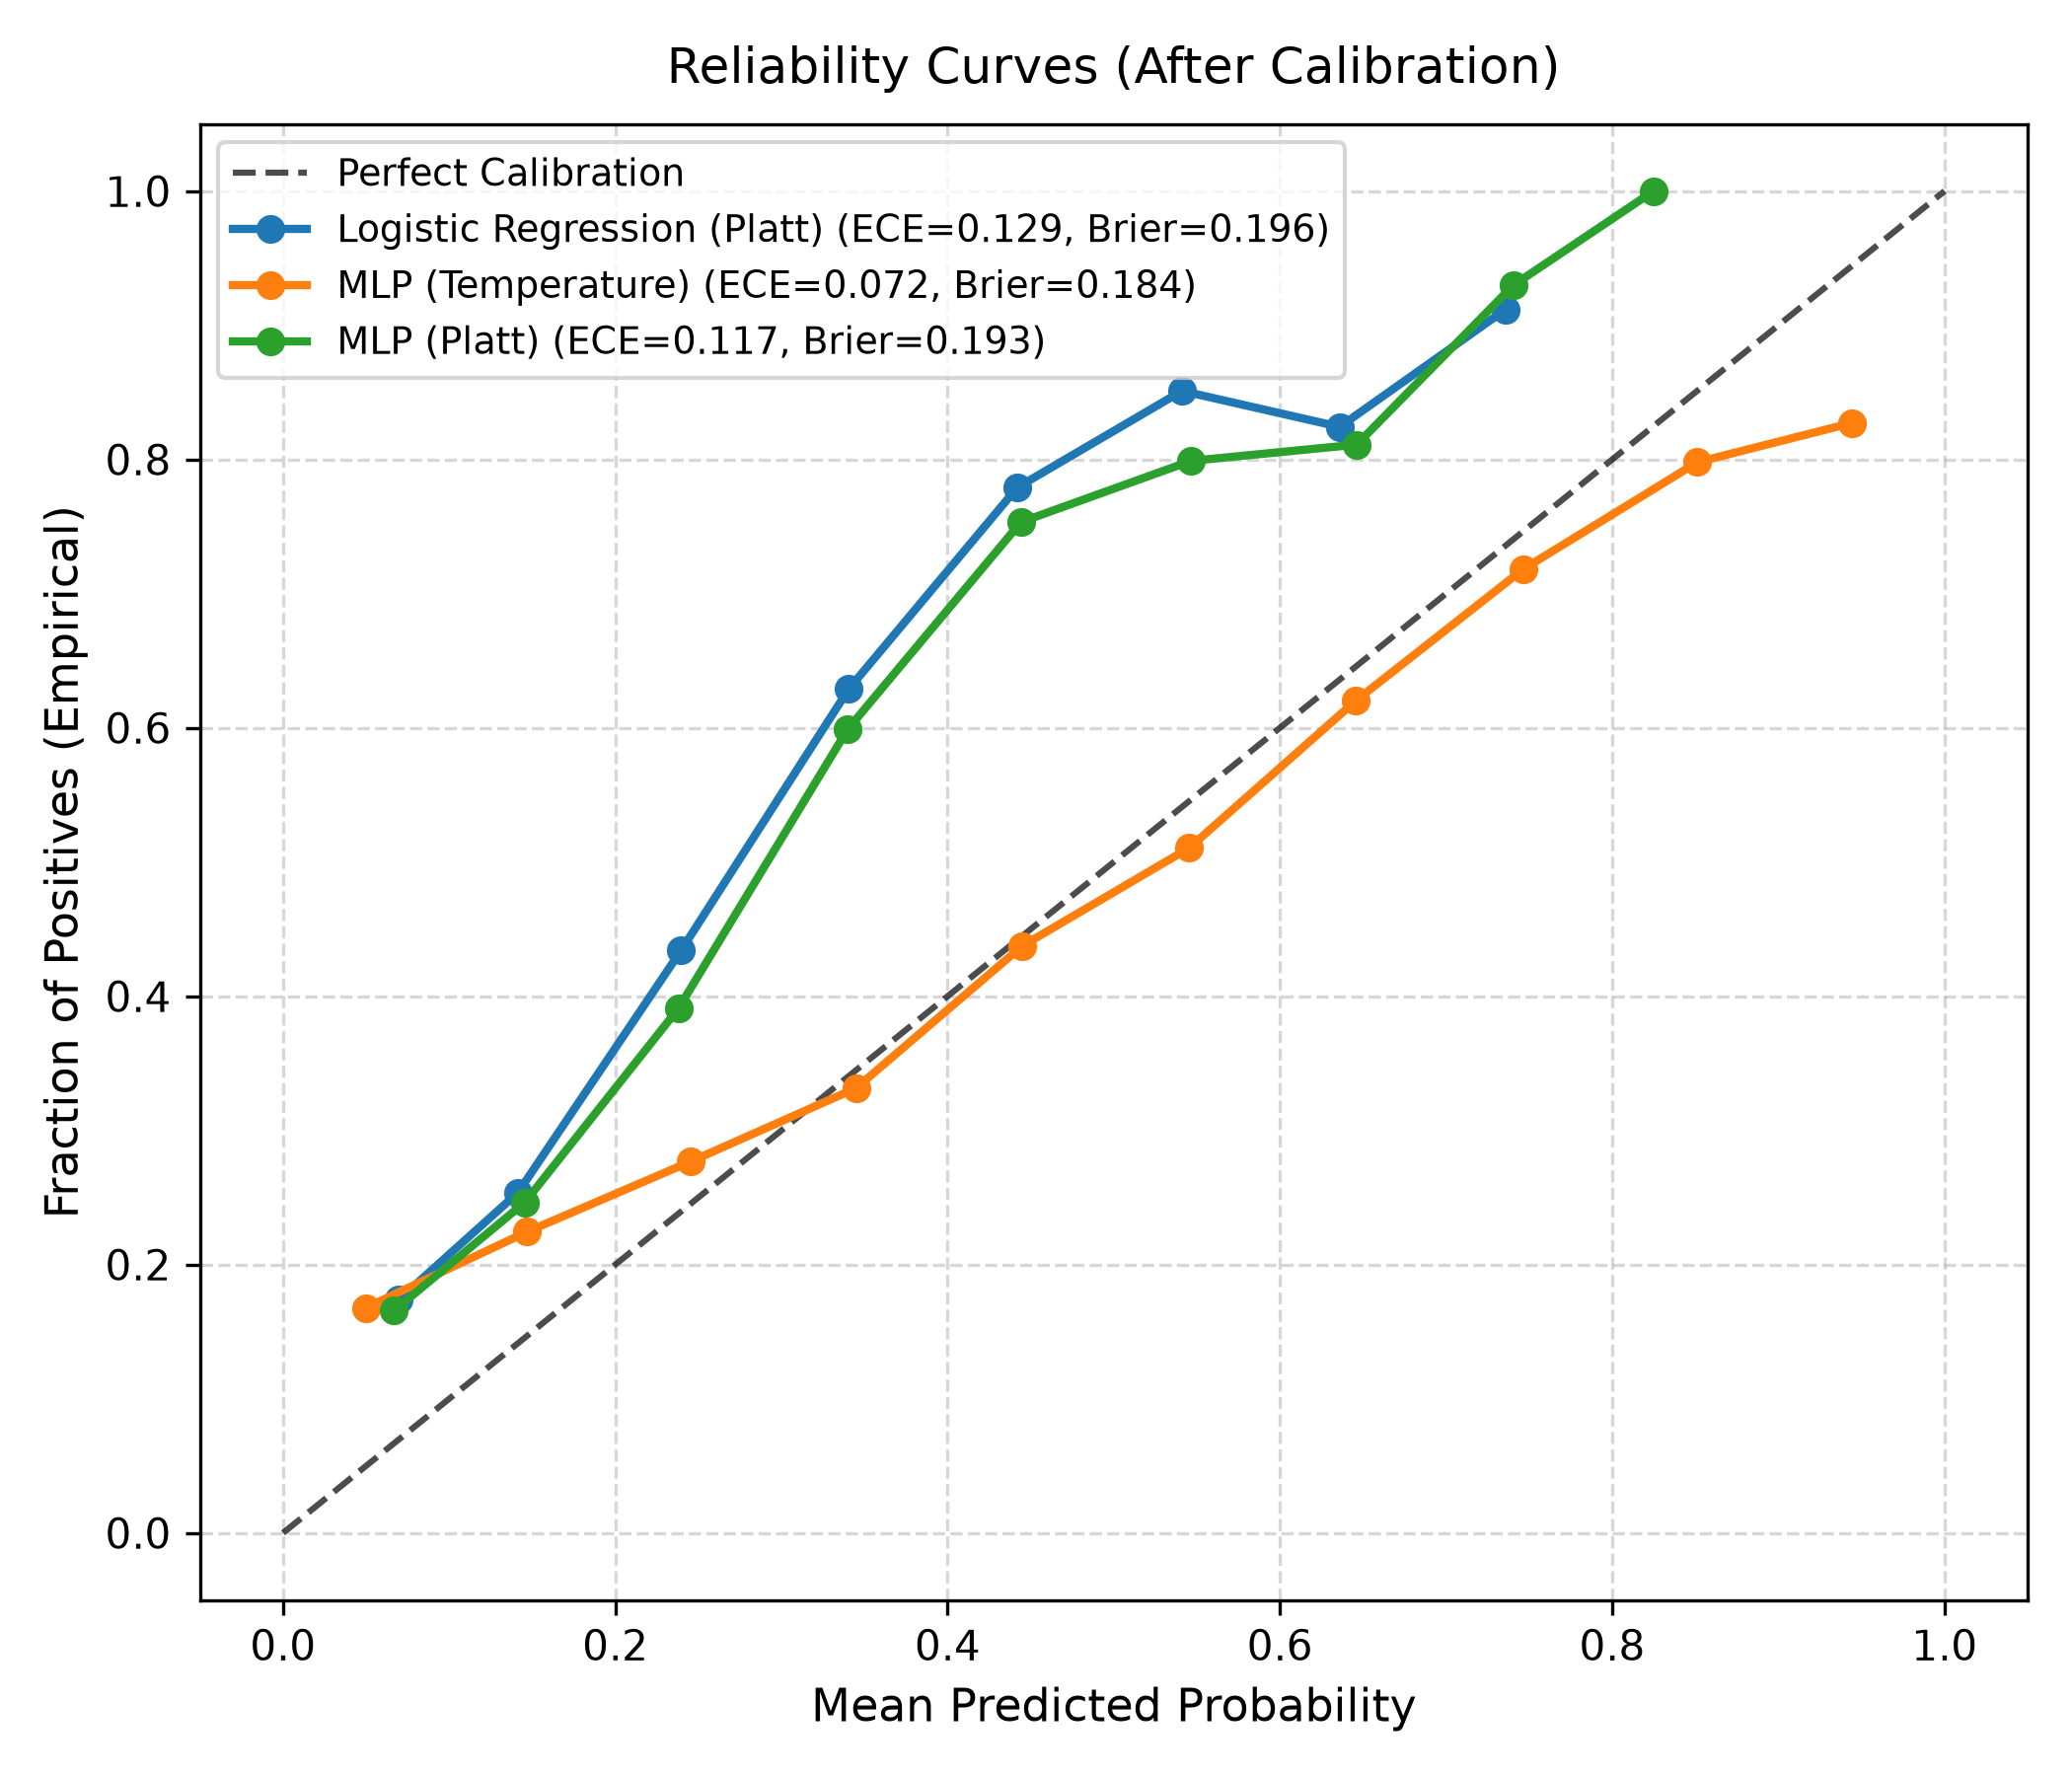

In [11]:
from src.phase2_calibration import plot_reliability_curves, plot_curves

before = {name: pt for name, (pv, pt) in raw.items()}
after = {
    "Logistic Regression (Platt)": platt["Logistic Regression"][1],
    "MLP (Temperature)":           mlp_temp[1],
    "MLP (Platt)":                 platt["PyTorch MLP"][1],
}

p1 = plot_reliability_curves(before, y_test, "Reliability Curves (Before Calibration)", "phase2_calibration_curves_before.png")
p2 = plot_reliability_curves(after,  y_test, "Reliability Curves (After Calibration)",  "phase2_calibration_curves_after.png")
display(Image(filename=str(p1), width=520))
display(Image(filename=str(p2), width=520))

## 9. PR and ROC curves
These use the raw probabilities. The order of flights is what matters here.

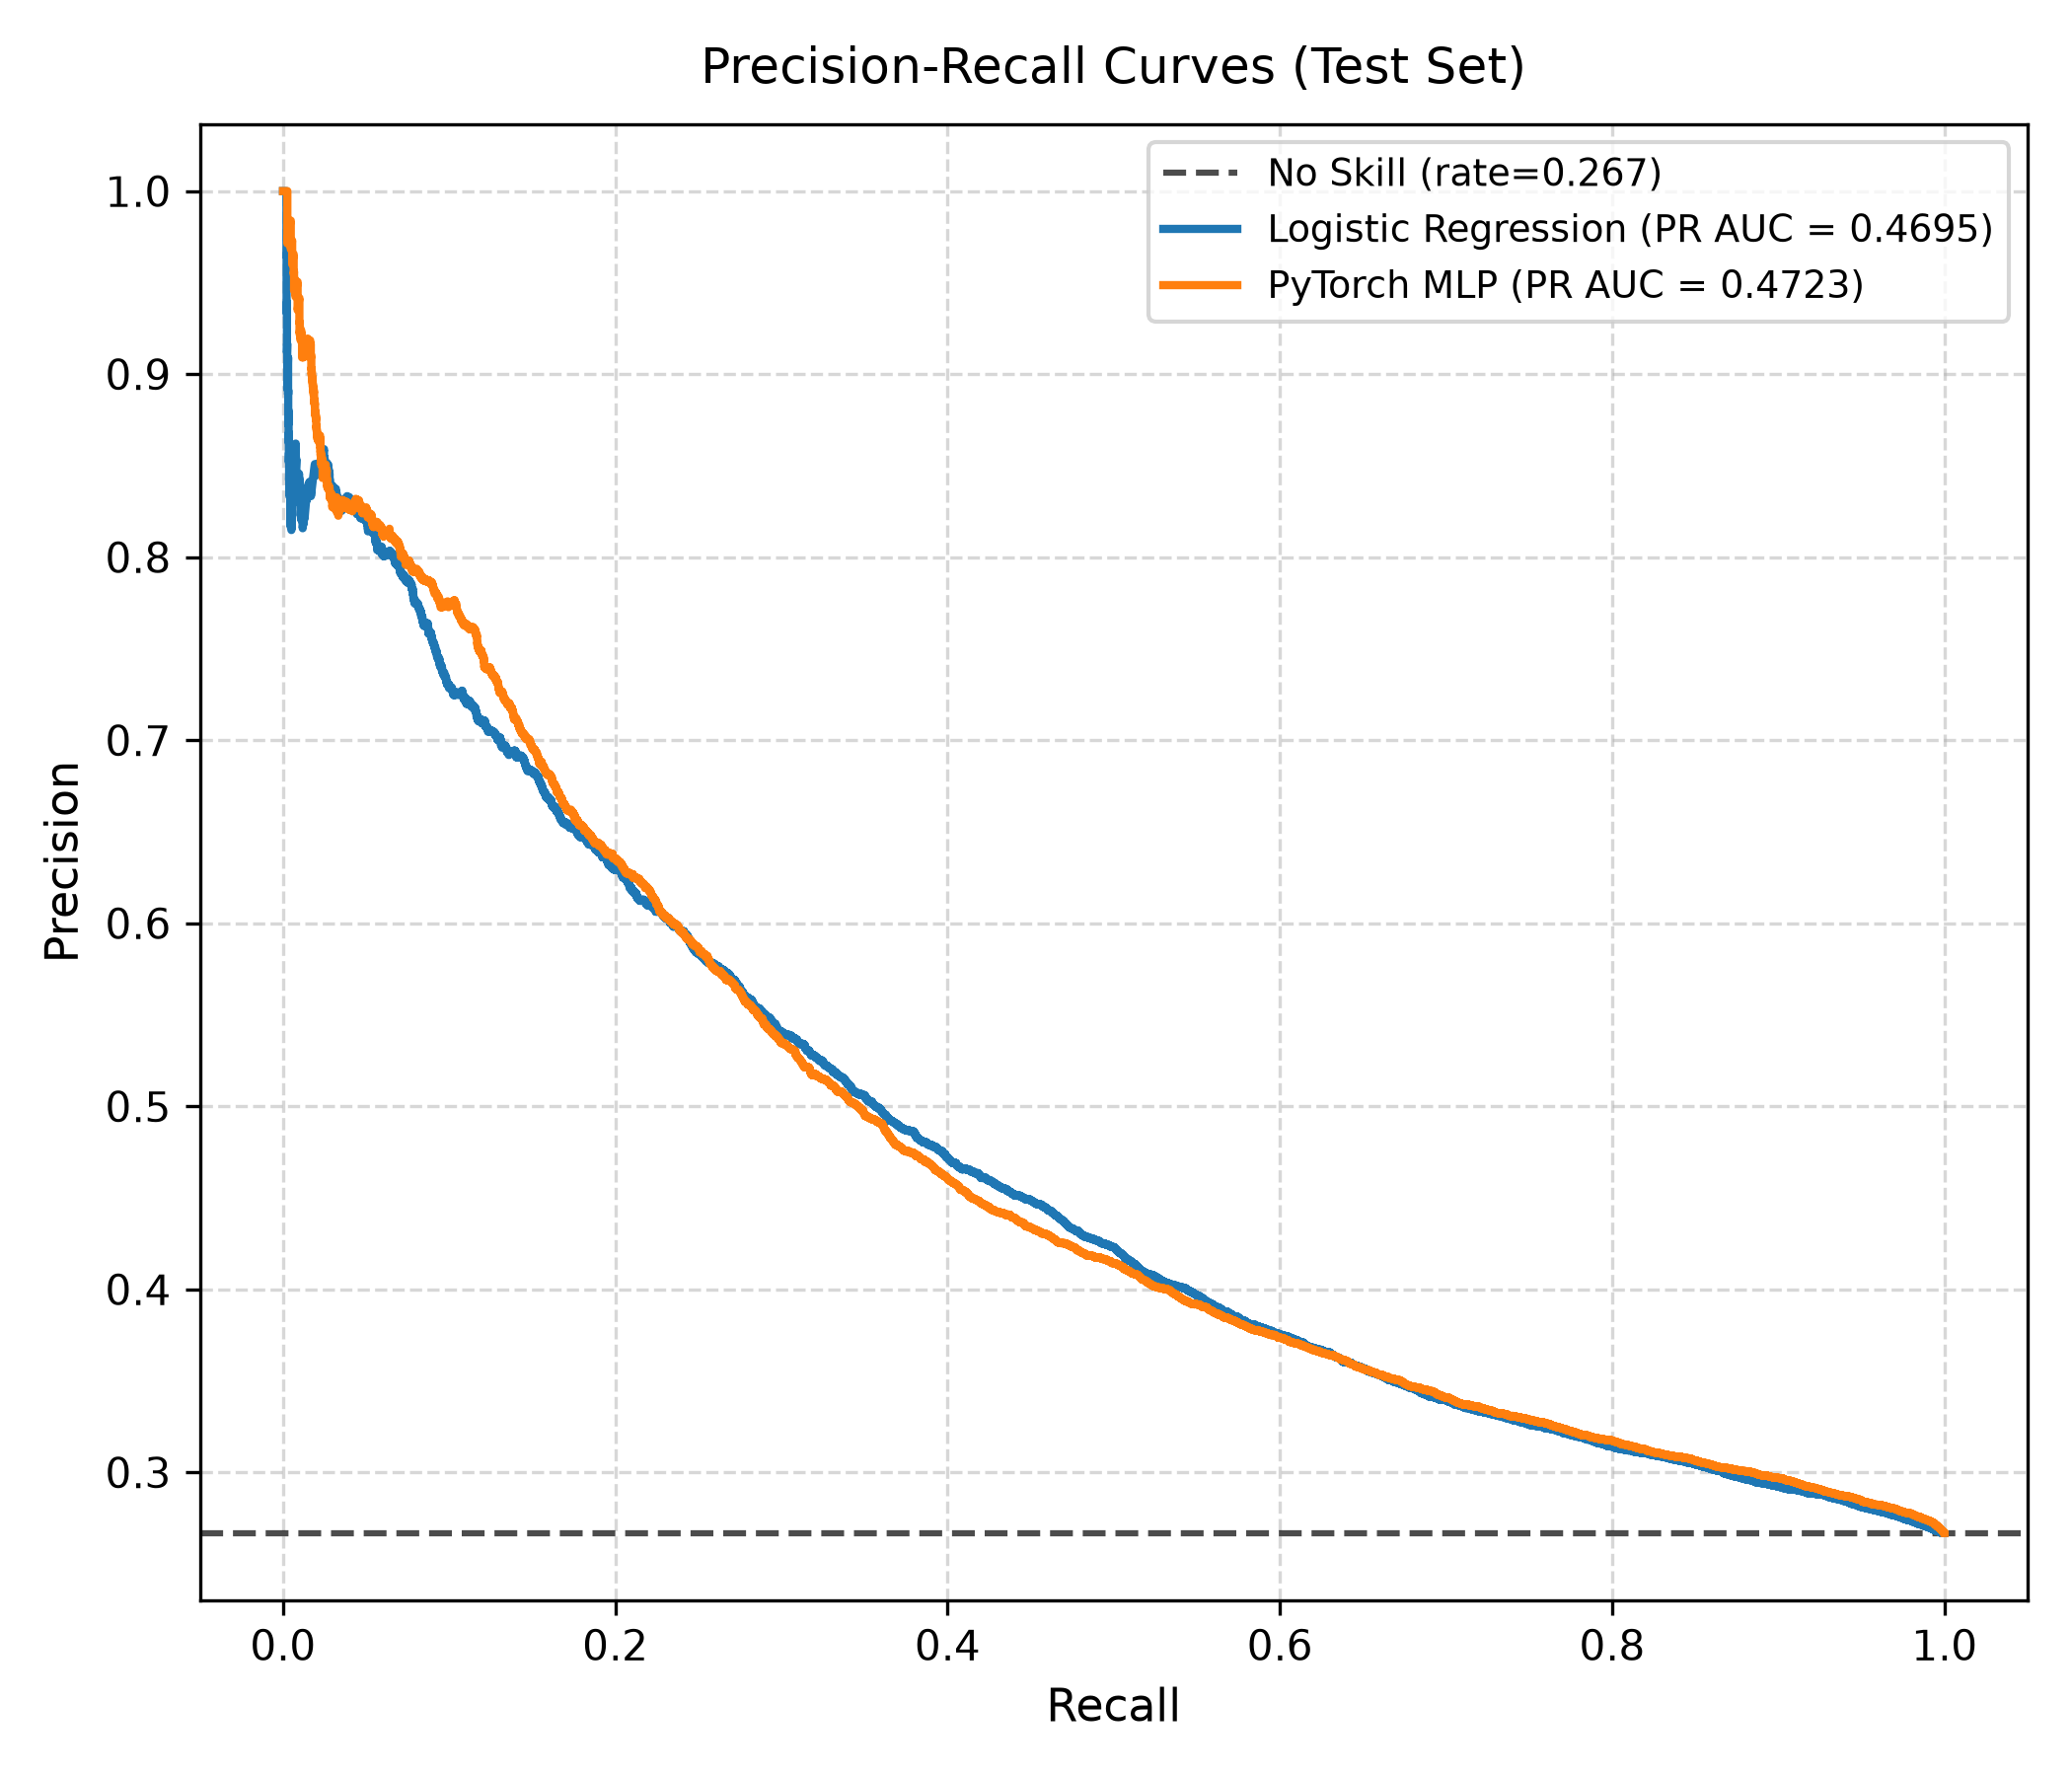

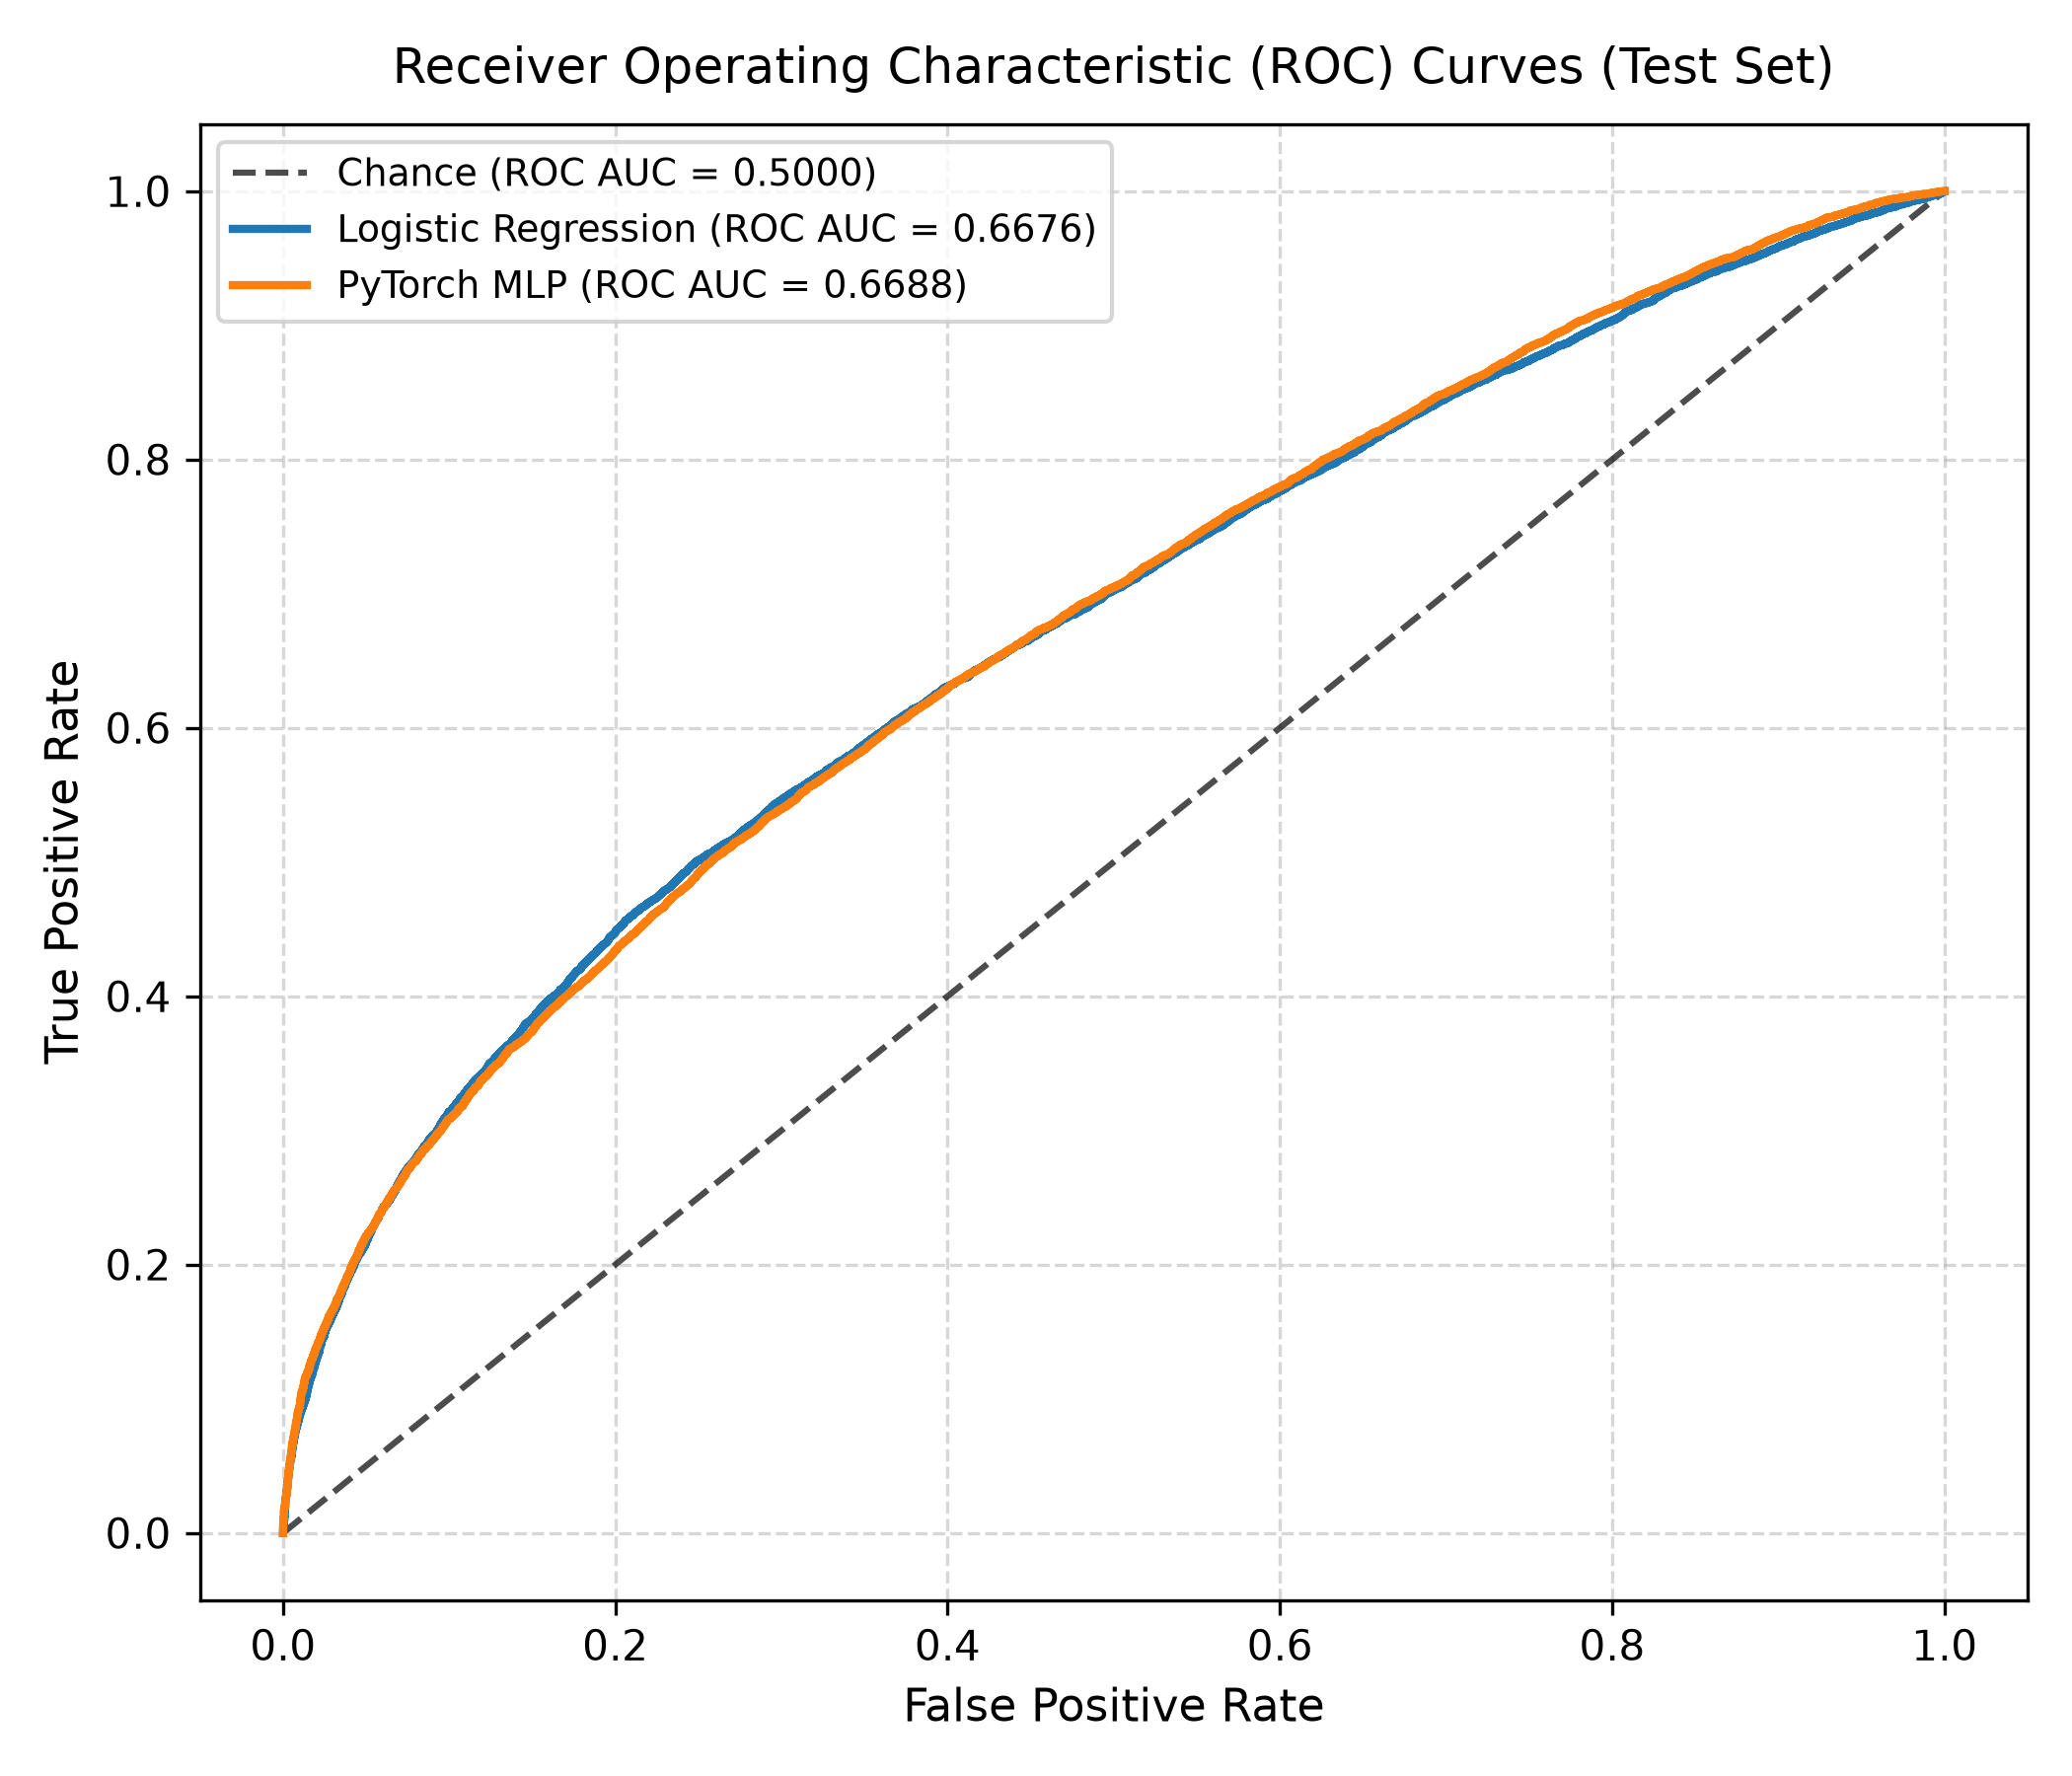

In [12]:
pr_path  = plot_curves(before, y_test, curve_type="pr",  save_filename="phase2_pr_curves.png")
roc_path = plot_curves(before, y_test, curve_type="roc", save_filename="phase2_roc_curves.png")
display(Image(filename=str(pr_path),  width=520))
display(Image(filename=str(roc_path), width=520))

## What we learned
- (We will write the real conclusions here after the results are checked.)
- Check section 4: if the model's mean predicted probability and the real delay rate are far apart on validation but close on test (or the other way round), then a fix fitted on validation can make the test calibration **worse**. This is a real finding, not a bug. We report it honestly.
- Calibration changes the probability values but not the order, so PR AUC and ROC AUC stay the same.